In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

PROCESSED_PATH = "data/processed"

customers = pd.read_csv(f"{PROCESSED_PATH}/customers.csv")

orders = pd.read_csv(
    f"{PROCESSED_PATH}/orders.csv",
    parse_dates=[
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

order_items = pd.read_csv(f"{PROCESSED_PATH}/order_items.csv")
products = pd.read_csv(f"{PROCESSED_PATH}/products.csv")
payments = pd.read_csv(f"{PROCESSED_PATH}/payments.csv")
reviews = pd.read_csv(
    f"{PROCESSED_PATH}/reviews.csv",
    parse_dates=["review_creation_date", "review_answer_timestamp"]
)
sellers = pd.read_csv(f"{PROCESSED_PATH}/sellers.csv")
geolocation = pd.read_csv(f"{PROCESSED_PATH}/geolocation.csv")
category_translation = pd.read_csv(
    f"{PROCESSED_PATH}/category_translation.csv"
)

print("Loaded all datasets successfully!")

Loaded all datasets successfully!


In [10]:
sales = order_items.copy()

sales = sales.merge(
    orders[["order_id", "order_purchase_timestamp"]],
    on="order_id",
    how="left"
)

sales["order_month"] = (
    sales["order_purchase_timestamp"].dt.to_period("M")
)

monthly_sales = (
    sales.groupby("order_month")["price"]
    .sum()
    .reset_index()
)

monthly_sales.head()

,order_month,price
0,2016-09,267.36
1,2016-10,49507.66
2,2016-12,10.90
3,2017-01,120312.87
4,2017-02,247303.02


In [12]:
# Đưa tháng về dạng datetime
monthly_sales["order_month"] = pd.to_datetime(
    monthly_sales["order_month"].astype(str)
)

# Đặt tháng làm chỉ mục
monthly_sales = monthly_sales.set_index("order_month")

# Bổ sung những tháng còn thiếu
monthly_sales = monthly_sales.resample("MS").sum()

# Đưa chỉ mục trở lại thành cột
monthly_sales = monthly_sales.reset_index()

print(monthly_sales)

   order_month       price
0   2016-09-01      267.36
1   2016-10-01    49507.66
2   2016-11-01        0.00
3   2016-12-01       10.90
4   2017-01-01   120312.87
5   2017-02-01   247303.02
6   2017-03-01   374344.30
7   2017-04-01   359927.23
8   2017-05-01   506071.14
9   2017-06-01   433038.60
10  2017-07-01   498031.48
11  2017-08-01   573971.68
12  2017-09-01   624401.69
13  2017-10-01   664219.43
14  2017-11-01  1010271.37
15  2017-12-01   743914.17
16  2018-01-01   950030.36
17  2018-02-01   844178.71
18  2018-03-01   983213.44
19  2018-04-01   996647.75
20  2018-05-01   996517.68
21  2018-06-01   865124.31
22  2018-07-01   895507.22
23  2018-08-01   854686.33
24  2018-09-01      145.00


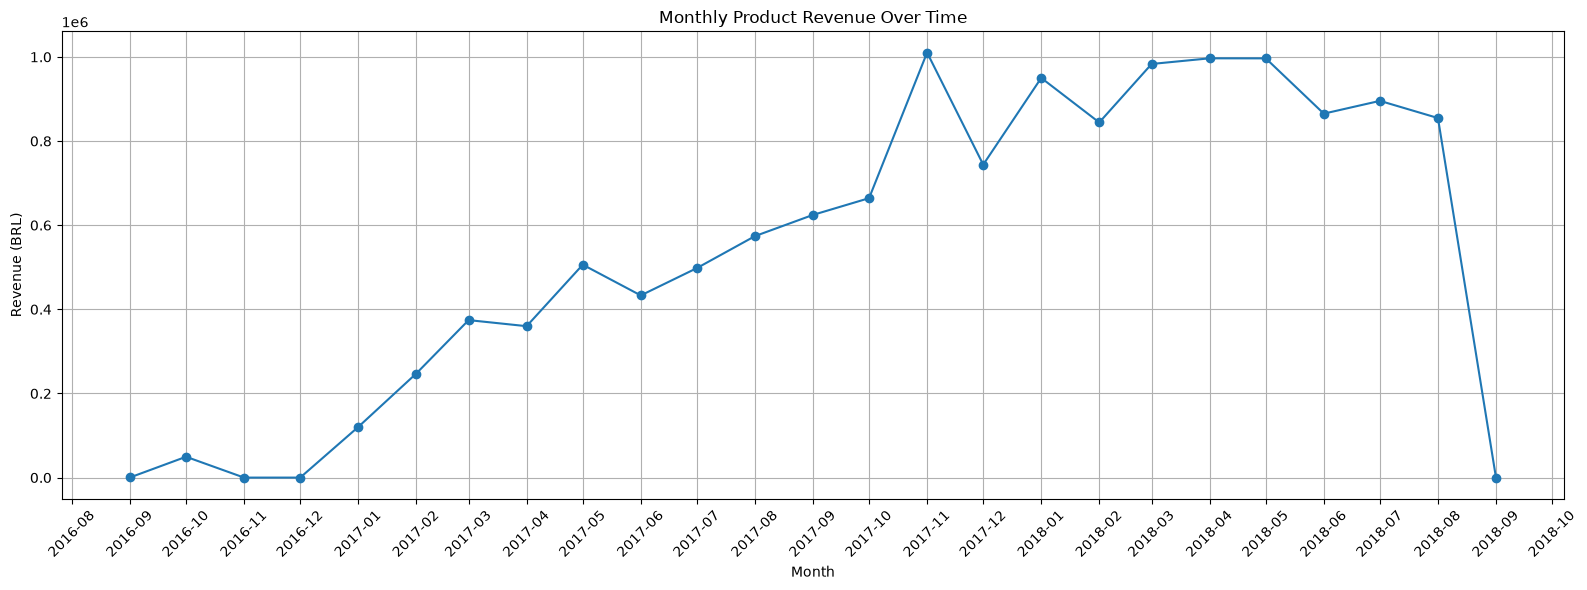

In [14]:
import matplotlib.dates as mdates

plt.figure(figsize=(16, 6))

plt.plot(
    monthly_sales["order_month"],
    monthly_sales["price"],
    marker="o"
)

plt.title("Monthly Product Revenue Over Time")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")

# Hiển thị nhãn mỗi tháng
plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=1))

# Định dạng nhãn theo năm-tháng
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [15]:
# Sao chép dữ liệu order_items
product_sales = order_items.copy()

# Kết hợp thông tin sản phẩm
product_sales = product_sales.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

# Kết hợp tên danh mục tiếng Anh
product_sales = product_sales.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

# Kiểm tra dữ liệu
product_sales.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_category_name_english
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,cool_stuff,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,pet_shop,pet_shop
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,moveis_decoracao,furniture_decor
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,perfumaria,perfumery
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,ferramentas_jardim,garden_tools


In [16]:
category_sales = (
    product_sales
    .groupby("product_category_name_english")
    .agg(
        total_revenue=("price", "sum"),
        total_quantity=("order_item_id", "count")
    )
    .reset_index()
    .sort_values(by="total_revenue", ascending=False)
)

category_sales.head(10)

,product_category_name_english,total_revenue,total_quantity
43,health_beauty,1258681.34,9670
70,watches_gifts,1205005.68,5991
7,bed_bath_table,1036988.68,11115
65,sports_leisure,988048.97,8641
15,computers_accessories,911954.32,7827
39,furniture_decor,729762.49,8334
20,cool_stuff,635290.85,3796
49,housewares,632248.66,6964
5,auto,592720.11,4235
42,garden_tools,485256.46,4347


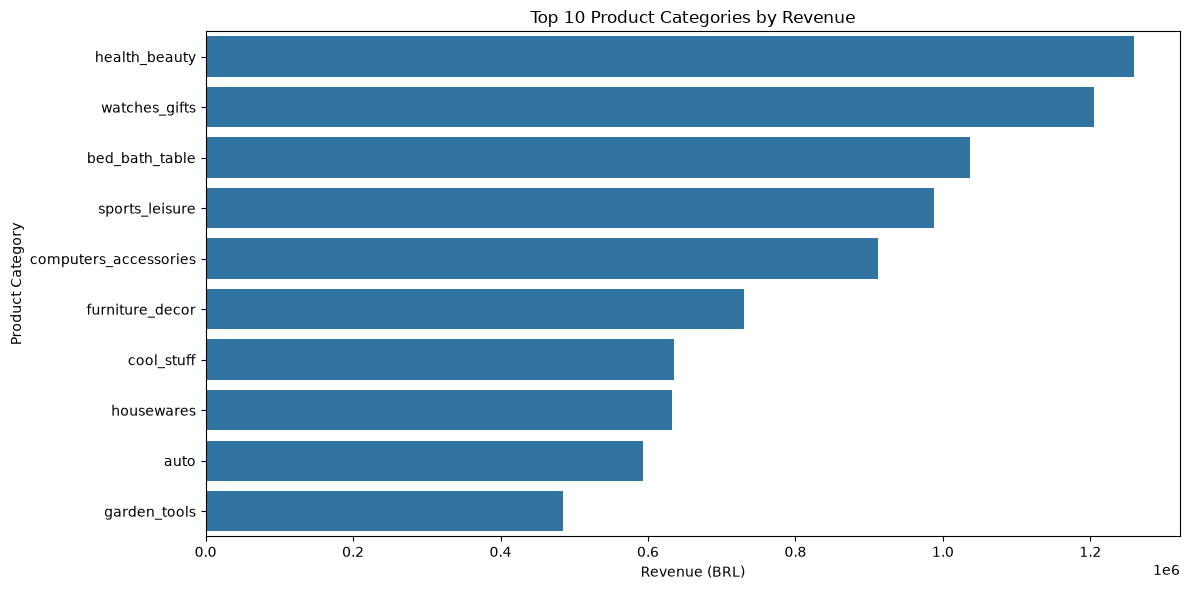

In [17]:
top_categories = category_sales.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_categories,
    x="total_revenue",
    y="product_category_name_english"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Revenue (BRL)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()